In [8]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency, mannwhitneyu, kruskal, spearmanr


In [2]:
df = pd.read_csv("Nigerian_Election_Dataset_clean.csv")
df.head(10)

,AgeGroup,Gender,Zone,HighestEducation,EmploymentStatus,MonthlyPersonalIncome,Q8_Understanding,Q10_INEC_Fair,Q6_Transparency,Q9_TrustCount,...,Q26_AcceptingMoneySurvival,Q27_SellingJustified,Q28_VoteForFinancialAssistance,Q29_LackAccountabilityEncouragesVoteSelling,Q30_ChooseCandidatesCompetence,Q31_RelyOnLeaders,Q32_ResearchCandidates,Q33_GiftsMoreLikelyWin,Q34_PeopleNoTrustElections,Target
0,26 - 35,Female,North Central,Secondary school certificate,Formal full-time,"Less than ₦20,000",2,2,2,1,...,5,3,5,2,5,3,2,3,3,0
1,60+,Male,North Central,Secondary school certificate,Formal full-time,"₦100,000 - ₦199,000",2,2,1,1,...,2,1,4,3,4,3,2,2,2,0
2,36 - 46,Female,North Central,Did not attend,Unemployed and looking,"₦100,000 - ₦199,000",1,1,1,1,...,2,1,2,3,4,4,4,3,4,1
3,26 - 35,Male,North West,Post Graduate,Unemployed and looking,"Less than ₦20,000",3,2,2,2,...,4,3,4,3,3,4,3,2,3,0
4,18 - 25,Female,North Central,Primary 6,Self-employed,"₦50,000 - ₦99,000",2,2,2,2,...,3,1,3,5,4,3,3,2,3,0
5,18 - 25,Male,South East,OND,Student,"₦100,000 - ₦199,000",2,2,1,1,...,4,2,3,2,2,3,4,2,4,0
6,18 - 25,Female,North West,Secondary school certificate,Student,"₦100,000 - ₦199,000",2,2,1,1,...,3,2,2,3,4,5,4,3,3,0
7,46 - 60,Female,North West,OND,Self-employed,"₦50,000 - ₦99,000",2,1,1,1,...,3,2,2,3,4,4,3,2,2,0
8,26 - 35,Female,North Central,B.Sc/HND/B.Eng,Student,"₦50,000 - ₦99,000",2,2,1,1,...,3,1,4,3,4,2,3,4,3,0
9,36 - 46,Male,South South,B.Sc/HND/B.Eng,Formal full-time,"₦50,000 - ₦99,000",3,2,1,2,...,3,1,3,4,5,3,3,3,3,0


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 444 entries, 0 to 443
Data columns (total 34 columns):
 #   Column                                       Non-Null Count  Dtype 
---  ------                                       --------------  ----- 
 0   AgeGroup                                     444 non-null    object
 1   Gender                                       444 non-null    object
 2   Zone                                         444 non-null    object
 3   HighestEducation                             444 non-null    object
 4   EmploymentStatus                             444 non-null    object
 5   MonthlyPersonalIncome                        444 non-null    object
 6   Q8_Understanding                             444 non-null    int64 
 7   Q10_INEC_Fair                                444 non-null    int64 
 8   Q6_Transparency                              444 non-null    int64 
 9   Q9_TrustCount                                444 non-null    int64 
 10  Q11_MaterialsA

In [4]:
df.describe(include='all')

,AgeGroup,Gender,Zone,HighestEducation,EmploymentStatus,MonthlyPersonalIncome,Q8_Understanding,Q10_INEC_Fair,Q6_Transparency,Q9_TrustCount,...,Q26_AcceptingMoneySurvival,Q27_SellingJustified,Q28_VoteForFinancialAssistance,Q29_LackAccountabilityEncouragesVoteSelling,Q30_ChooseCandidatesCompetence,Q31_RelyOnLeaders,Q32_ResearchCandidates,Q33_GiftsMoreLikelyWin,Q34_PeopleNoTrustElections,Target
count,444,444,444,444,444,444,444.000000,444.000000,444.000000,444.000000,...,444.000000,444.000000,444.000000,444.000000,444.000000,444.000000,444.000000,444.000000,444.000000,444.000000
unique,5,3,6,6,6,6,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,18 - 25,Male,North West,Secondary school certificate,Formal full-time,"₦20,000 - ₦49,000",NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,161,232,104,149,128,111,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,NaN,NaN,NaN,NaN,2.141892,1.743243,1.369369,1.425676,...,3.281532,1.885135,3.119369,3.380631,3.101351,3.004505,3.198198,3.022523,3.610360,0.421171
std,NaN,NaN,NaN,NaN,NaN,NaN,0.723767,0.571580,0.580774,0.499542,...,0.991850,0.719201,1.043818,0.894772,0.953122,0.943064,0.946132,1.045008,0.878117,0.739472
min,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000
25%,NaN,NaN,NaN,NaN,NaN,NaN,2.000000,1.000000,1.000000,1.000000,...,3.000000,1.000000,2.000000,3.000000,2.000000,2.000000,3.000000,2.000000,3.000000,0.000000
50%,NaN,NaN,NaN,NaN,NaN,NaN,2.000000,2.000000,1.000000,1.000000,...,3.000000,2.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,4.000000,0.000000
75%,NaN,NaN,NaN,NaN,NaN,NaN,3.000000,2.000000,2.000000,2.000000,...,4.000000,2.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,1.000000


In [5]:
print(df.isna().sum())

AgeGroup                                       0
Gender                                         0
Zone                                           0
HighestEducation                               0
EmploymentStatus                               0
MonthlyPersonalIncome                          0
Q8_Understanding                               0
Q10_INEC_Fair                                  0
Q6_Transparency                                0
Q9_TrustCount                                  0
Q11_MaterialsAdequate                          0
Q12_INEC_onTime                                0
Q13_ViolenceCommon                             0
Q14_OfficersInfluence                          0
Q16_SafeParticipation                          0
Q17_VoteForState                               0
Q18_VoteForFriend                              0
Q19_Pressured                                  0
Q20_CampaignActiveDeserve                      0
Q21_GiftsShowCare                              0
Q22_ReceivingGiftsNo

### Categorical distributions

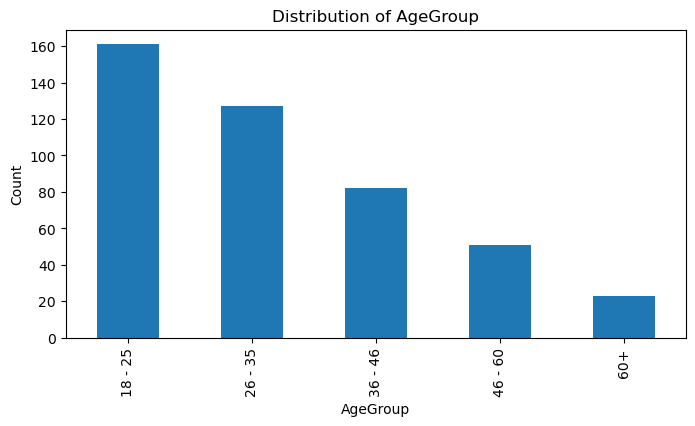

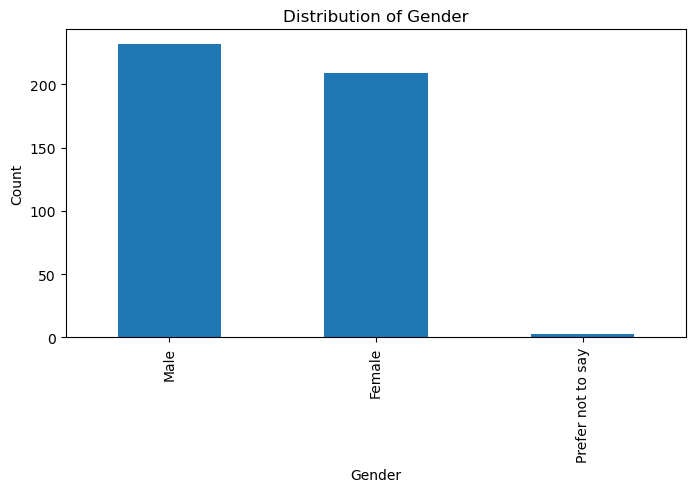

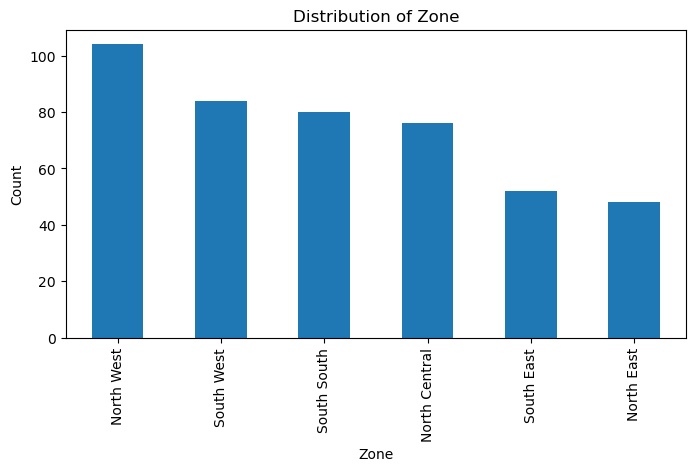

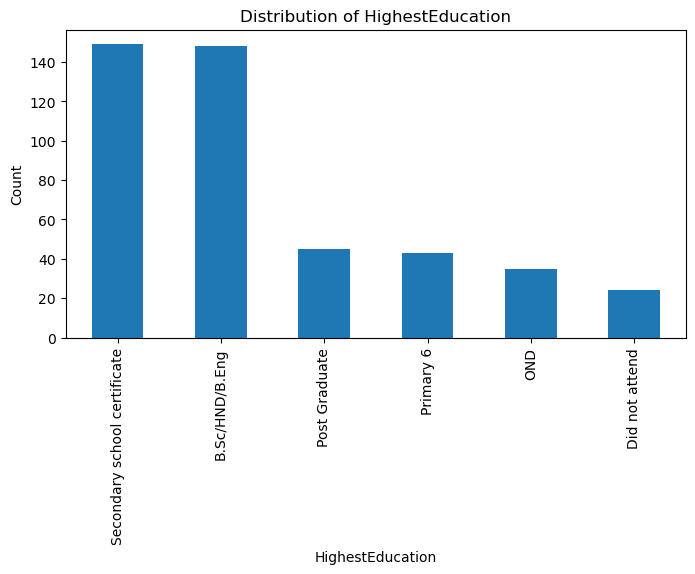

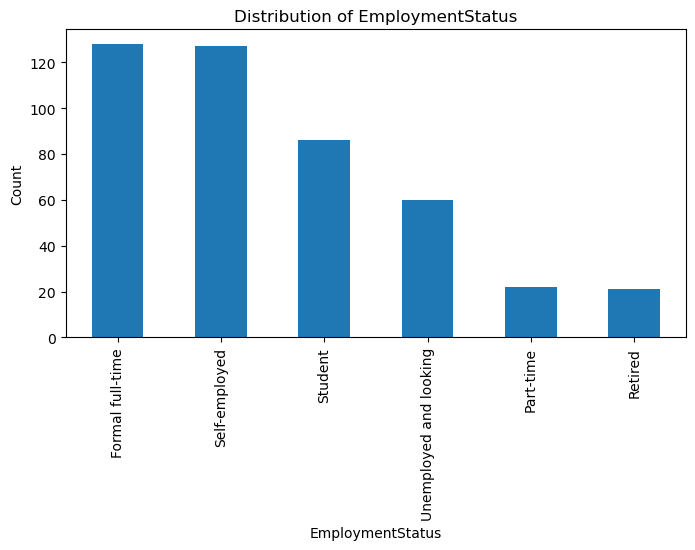

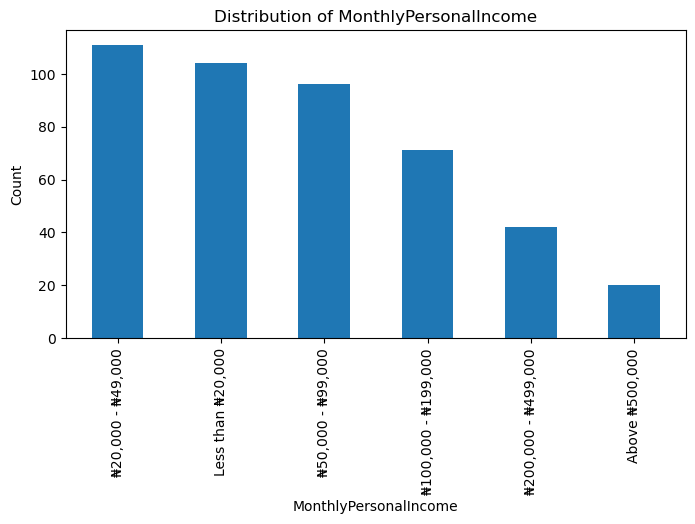

In [9]:
categorical_cols = ["AgeGroup", "Gender", "Zone", 
                    "HighestEducation", "EmploymentStatus", 
                    "MonthlyPersonalIncome"]

for col in categorical_cols:
    plt.figure(figsize=(8,4))
    df[col].value_counts().plot(kind='bar')
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.show()


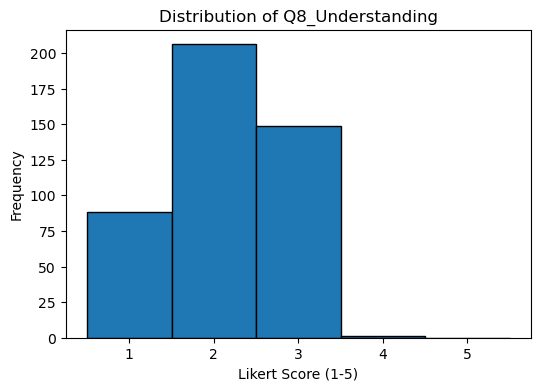

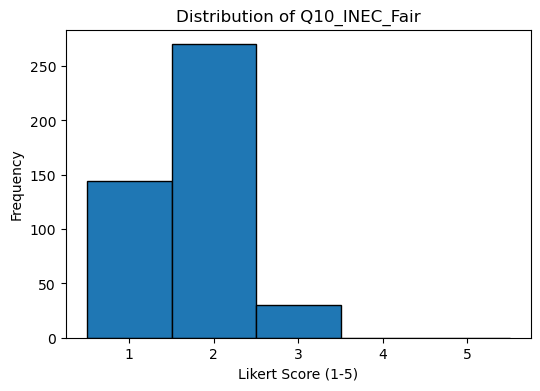

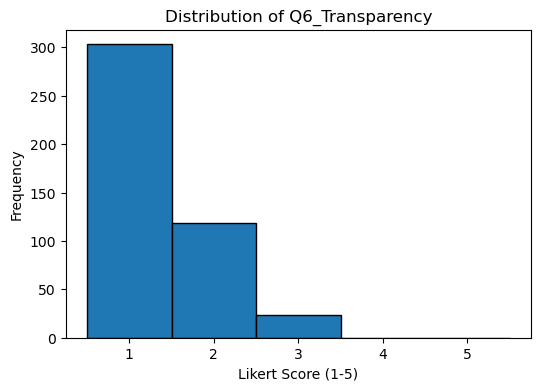

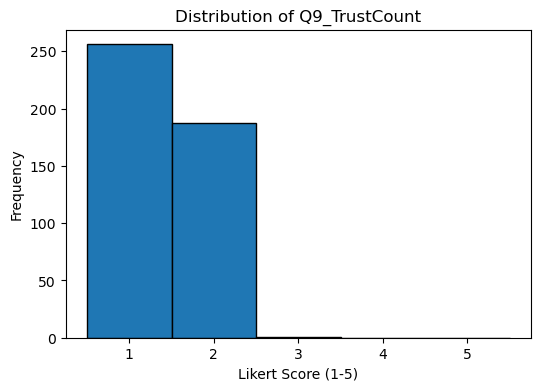

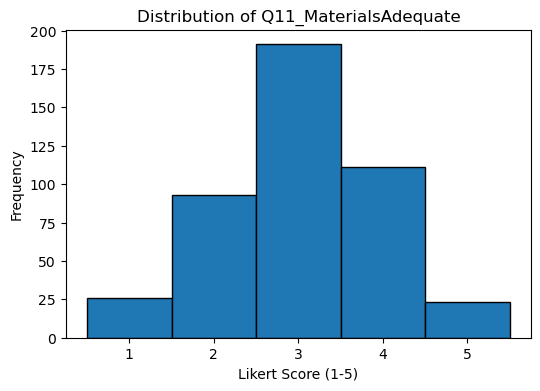

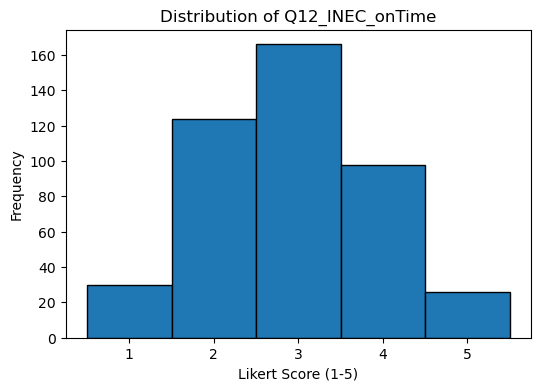

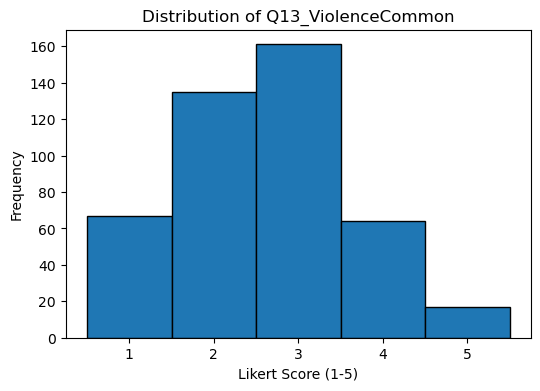

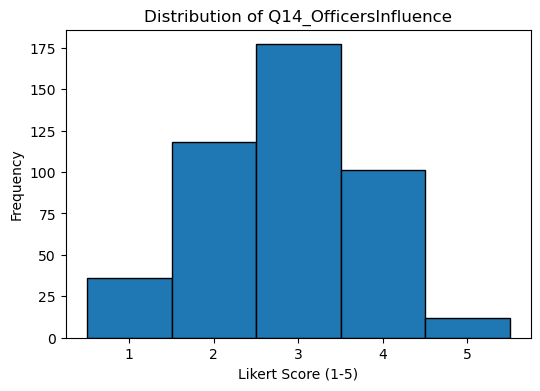

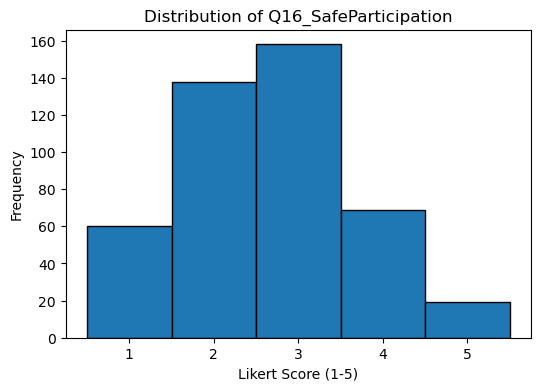

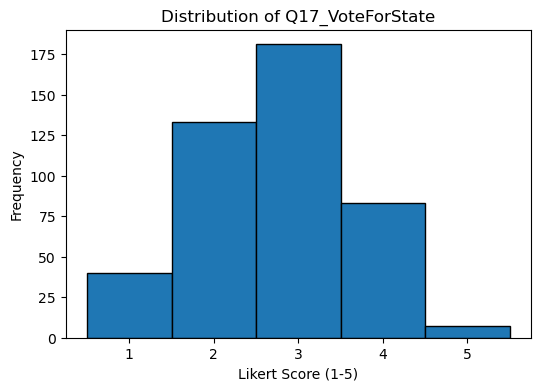

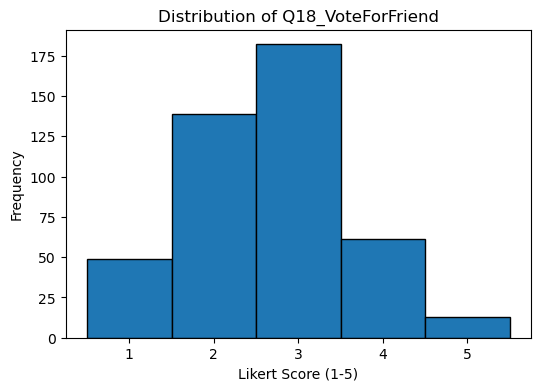

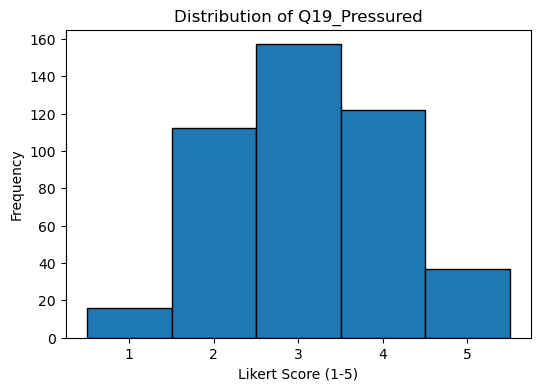

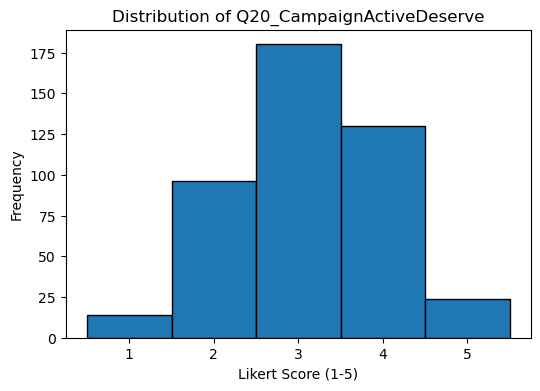

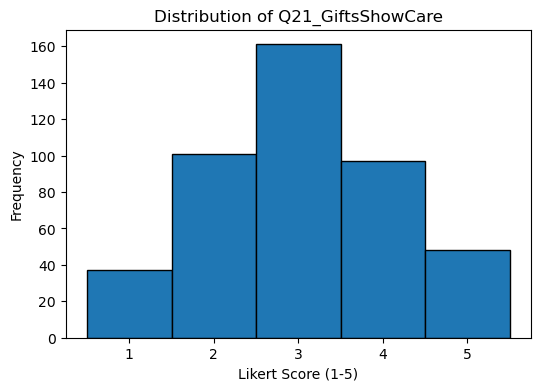

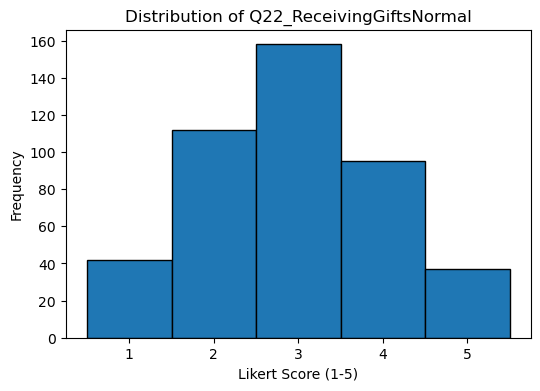

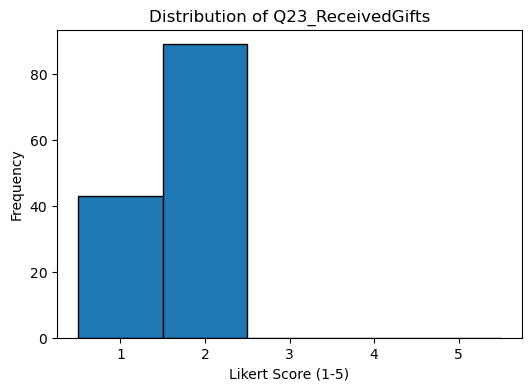

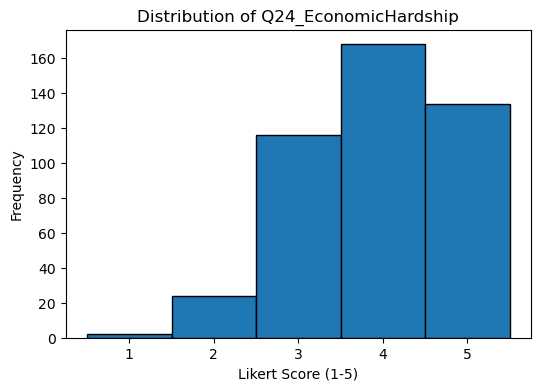

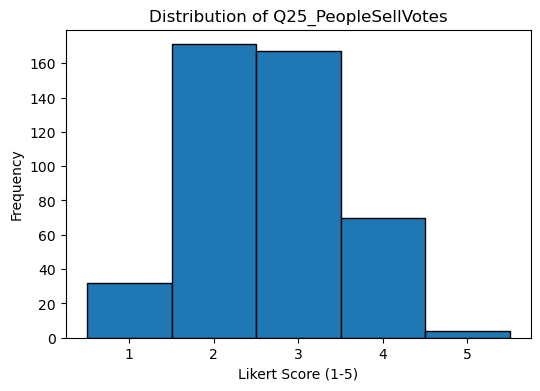

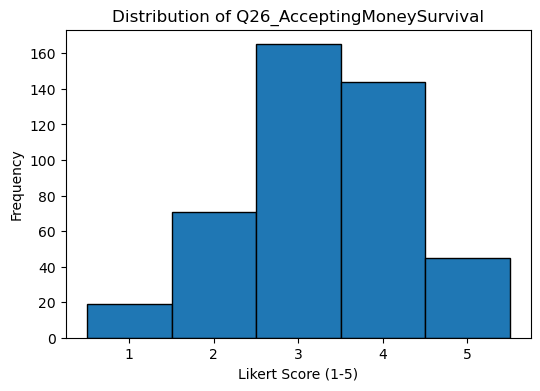

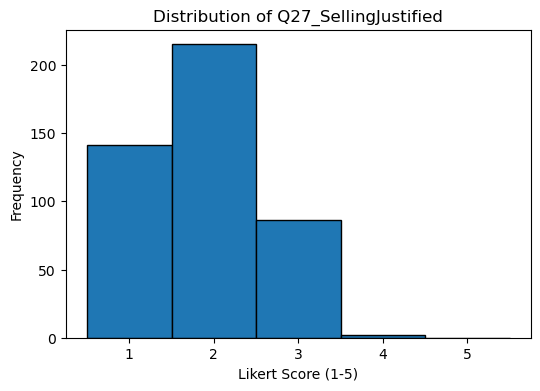

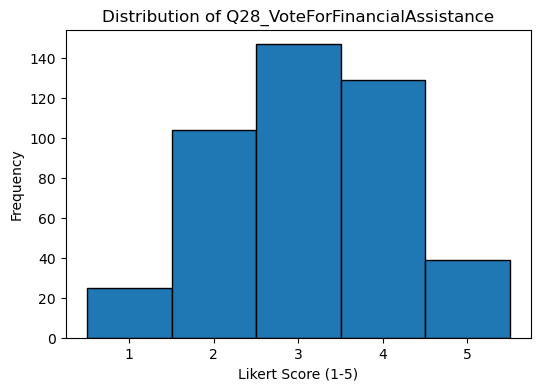

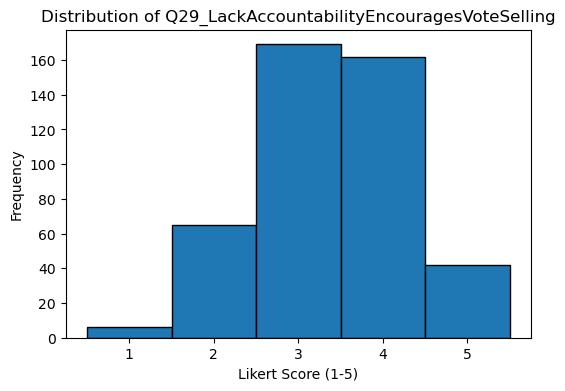

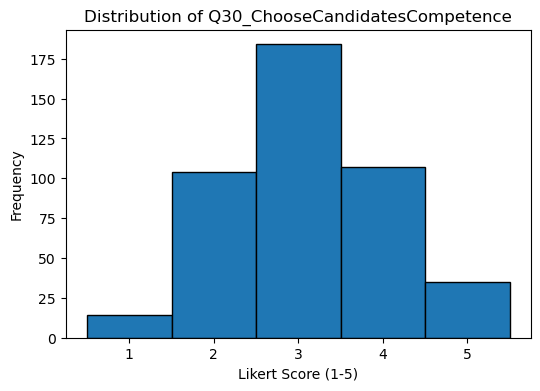

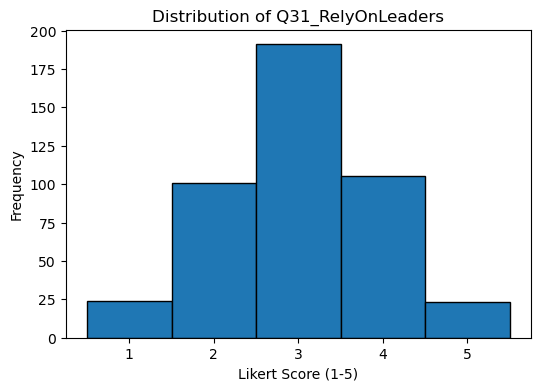

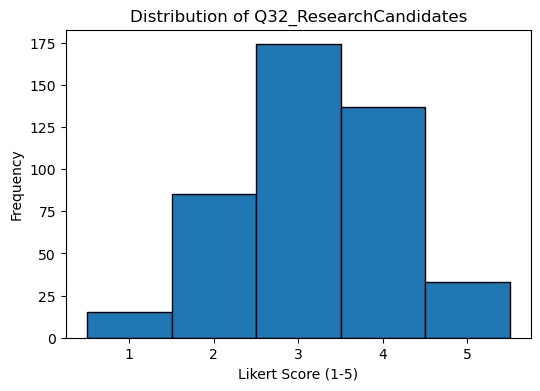

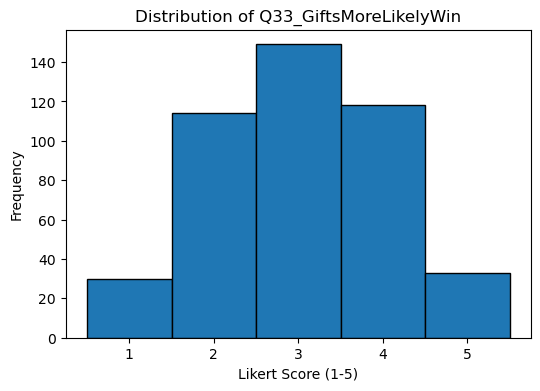

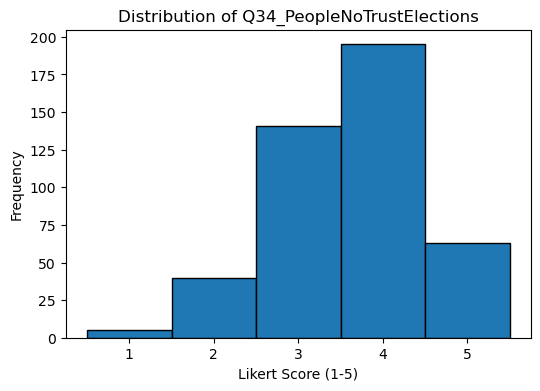

In [10]:
likert_cols = [c for c in df.columns if c.startswith("Q")]

for col in likert_cols:
    plt.figure(figsize=(6,4))
    plt.hist(df[col], bins=np.arange(1,7)-0.5, edgecolor='black')
    plt.title(f"Distribution of {col}")
    plt.xlabel("Likert Score (1-5)")
    plt.ylabel("Frequency")
    plt.show()